In medical image classification, recall is especially important because false negatives may represent missed PCOS cases.

Therefore, threshold analysis was performed instead of relying only on the default threshold of 0.5.

Different thresholds were evaluated to improve the balance between precision and recall. The optimal threshold was selected based on F1-score and recall performance.

# 04. Model Evaluation and Threshold Analysis

This notebook evaluates the final selected CNN model on the unseen test dataset.

The selected final model is the improved regularized CNN model (V3), because it achieved the best validation performance, strongest generalization capability, and the most stable learning behavior among all conducted experiments.

The evaluation includes:

- test loss and accuracy
- precision, recall, and AUC
- confusion matrix
- ROC curve
- threshold analysis for medical classification

Threshold analysis is important in medical image classification because false negatives may represent missed PCOS cases.

---



# 1. Load the Test Set and Final CNN Model

The test set is loaded only during the final evaluation stage to ensure unbiased performance estimation.

The final selected model path:

`C:\Users\MHawa\OneDrive\Desktop\DL project\models\v3_regularized_cnn_final.keras`

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

## 2. Fix Image Paths

The CSV file contains image paths saved during earlier preprocessing.  
Since the notebook may run from a different folder, the image paths are rebuilt using the project directory, class label, and image filename.

In [37]:
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\MHawa\OneDrive\Desktop\DL project")

DATA_ROOT = PROJECT_DIR / "data" / "PCOS" / "PCOS"

TEST_CSV = PROJECT_DIR / 'data' / "processed" / "test_df.csv"

MODEL_PATH = PROJECT_DIR / "models" / "v3_regularized_cnn_final.keras"

FIGURES_DIR = PROJECT_DIR / "figures"

FIGURES_DIR.mkdir(exist_ok=True)

# =========================================
# Load Test DataFrame
# =========================================

test_df = pd.read_csv(TEST_CSV)

print("Test dataframe shape:", test_df.shape)

test_df.head()

Test dataframe shape: (1768, 5)


,image_path,label,width,height,label_encoded
0,data\PCOS\PCOS\noninfected\Image_SetB994.jpg,noninfected,984,848,0
1,data\PCOS\PCOS\noninfected\Image_SetA800.jpg,noninfected,315,160,0
2,data\PCOS\PCOS\noninfected\Image_resize_671 (...,noninfected,984,848,0
3,data\PCOS\PCOS\infected\Image_SETA_716.jpg,infected,300,300,1
4,data\PCOS\PCOS\infected\Image_resize_343.jpg,infected,171,171,1


In [38]:
from pathlib import Path

# Fix Relative Image Paths
test_df["image_name"] = test_df["image_path"].apply(lambda x: Path(x).name)

test_df["image_path"] = test_df.apply(
    lambda row: str(DATA_ROOT / row["label"] / row["image_name"]),
    axis=1
)

print(test_df["image_path"].head())

existing_files = test_df["image_path"].apply(lambda p: Path(p).exists()).sum()
missing_files = len(test_df) - existing_files

print("Existing files:", existing_files)
print("Missing files:", missing_files)
print("Total files:", len(test_df))

0    C:\Users\MHawa\OneDrive\Desktop\DL project\dat...
1    C:\Users\MHawa\OneDrive\Desktop\DL project\dat...
2    C:\Users\MHawa\OneDrive\Desktop\DL project\dat...
3    C:\Users\MHawa\OneDrive\Desktop\DL project\dat...
4    C:\Users\MHawa\OneDrive\Desktop\DL project\dat...
Name: image_path, dtype: str
Existing files: 1768
Missing files: 0
Total files: 1768


## 3. Create the Test Image Generator

Only normalization is applied to the test set.  
No augmentation is used during testing because the test set must represent real unseen images.

In [39]:
test_datagen = ImageDataGenerator()

test_generator = test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="image_path",
    y_col="label",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    classes=["infected", "noninfected"],
    shuffle=False
)

print(test_generator.class_indices)

Found 1768 validated image filenames belonging to 2 classes.
{'infected': 0, 'noninfected': 1}


# 4. Load the Final Selected CNN Model

In [40]:
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import (
    RandomBrightness,
    RandomContrast,
    RandomRotation,
    RandomZoom,
    RandomFlip,
    RandomTranslation
)

MODEL_PATH = r"C:\Users\MHawa\OneDrive\Desktop\DL project\models\v3_regularized_cnn_final.keras"

model = load_model(
    MODEL_PATH,
    custom_objects={
        "RandomBrightness": RandomBrightness,
        "RandomContrast": RandomContrast,
        "RandomRotation": RandomRotation,
        "RandomZoom": RandomZoom,
        "RandomFlip": RandomFlip,
        "RandomTranslation": RandomTranslation,
    }
)

print("Final model loaded successfully.")

Final model loaded successfully.


# 5. Evaluate the Model on the Test Set

The final model is evaluated on the untouched test dataset to estimate real generalization performance.

In [41]:
test_results = model.evaluate(test_generator, verbose=1)

for name, value in zip(model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

56/56 ━━━━━━━━━━━━━━━━━━━━ 25s 430ms/step - accuracy: 0.9225 - auc: 0.9824 - loss: 0.2413 - precision: 0.8487 - recall: 0.9947
loss: 0.2413
compile_metrics: 0.9225


## 7. Confusion Matrix at Threshold 0.50

The confusion matrix shows the number of correct and incorrect predictions for each class.

In medical diagnosis, false negatives are especially important because they represent infected cases that were missed by the model.

In [44]:
# =========================================
# Generate Predictions Correctly
# =========================================

import numpy as np

test_generator.reset()

# Probabilities from model
y_prob_noninfected = model.predict(
    test_generator,
    verbose=1
).ravel()

# Original labels from generator
y_true_original = np.array(test_generator.classes)

# =========================================
# Training class order:
# infected = 0
# noninfected = 1
#
# Convert to medical interpretation:
# noninfected = 0
# infected = 1
# =========================================

y_true = (y_true_original == 0).astype(int)

# Convert probabilities so:
# higher probability = infected
y_prob = 1 - y_prob_noninfected

print("y_true shape:", y_true.shape)
print("y_prob shape:", y_prob.shape)

print("First 10 labels:", y_true[:10])
print("First 10 probabilities:", y_prob[:10])

56/56 ━━━━━━━━━━━━━━━━━━━━ 29s 523ms/step
y_true shape: (1768,)
y_prob shape: (1768,)
First 10 labels: [0 0 0 1 1 1 1 0 1 0]
First 10 probabilities: [1.47094250e-01 7.04586506e-04 1.09567165e-01 9.91564453e-01
 9.97375309e-01 9.92902815e-01 2.02789187e-01 7.04586506e-04
 9.99727547e-01 3.59489799e-01]


In [45]:
default_threshold = 0.50

y_pred_05 = (y_prob >= default_threshold).astype(int)

class_names = ["noninfected", "infected"]

accuracy_05 = accuracy_score(y_true, y_pred_05)
precision_05 = precision_score(y_true, y_pred_05, zero_division=0)
recall_05 = recall_score(y_true, y_pred_05, zero_division=0)
f1_05 = f1_score(y_true, y_pred_05, zero_division=0)
auc_05 = roc_auc_score(y_true, y_prob)

metrics_05 = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "AUC"],
    "Score": [accuracy_05, precision_05, recall_05, f1_05, auc_05]
})

metrics_05.to_csv(FIGURES_DIR / "metrics_threshold_0.5.csv", index=False)

metrics_05

,Metric,Score
0,Accuracy,0.922511
1,Precision,0.995501
2,Recall,0.869352
3,F1-score,0.928159
4,AUC,0.982258


In [46]:
print(
    classification_report(
        y_true,
        y_pred_05,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

 noninfected     0.8487    0.9947    0.9159       750
    infected     0.9955    0.8694    0.9282      1018

    accuracy                         0.9225      1768
   macro avg     0.9221    0.9320    0.9220      1768
weighted avg     0.9332    0.9225    0.9230      1768



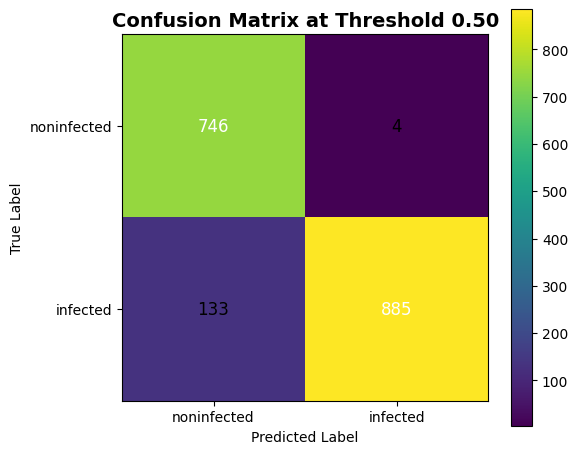

array([[746,   4],
       [133, 885]])

In [47]:
cm_05 = confusion_matrix(y_true, y_pred_05)

plt.figure(figsize=(6, 5))
plt.imshow(cm_05, cmap="viridis")

plt.title("Confusion Matrix at Threshold 0.50", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks([0, 1], class_names)
plt.yticks([0, 1], class_names)

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm_05[i, j],
            ha="center",
            va="center",
            fontsize=12,
            color="white" if cm_05[i, j] > cm_05.max() / 2 else "black"
        )

plt.colorbar()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix_threshold_050.png", dpi=300)
plt.show()

cm_05

## 8. ROC Curve

The ROC curve evaluates how well the model separates infected and noninfected classes across different thresholds.  
A higher AUC indicates better class separation.

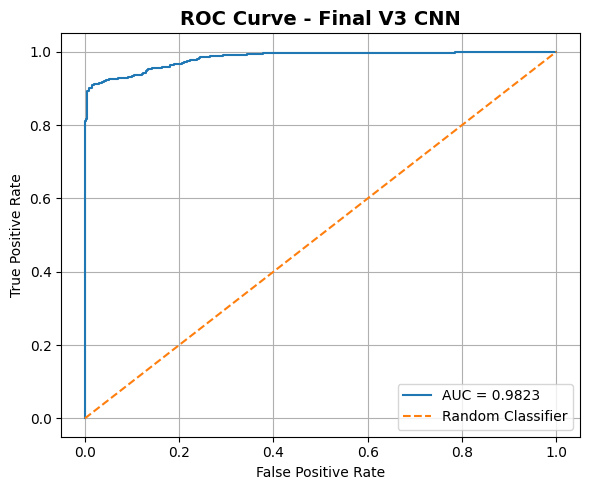

ROC-AUC: 0.9823


In [48]:
# =========================================================
# ROC Curve
# Medical interpretation:
# 0 = noninfected
# 1 = infected
# =========================================================

from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, roc_thresholds = roc_curve(y_true, y_prob)
auc_score = roc_auc_score(y_true, y_prob)

plt.figure(figsize=(6, 5))

plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve - Final V3 CNN", fontsize=14, fontweight="bold")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "roc_curve_final_v3.png", dpi=300)
plt.show()

print("ROC-AUC:", round(auc_score, 4))

## 9. Threshold Analysis

The default threshold of 0.50 may not always be optimal, especially in medical classification.

Because missing an infected PCOS case can be more serious than a false alarm, recall is very important.  
Therefore, different thresholds are tested to study the trade-off between precision, recall, and F1-score.

This threshold adjustment is applied only during evaluation. It does not change the trained CNN model.

In [50]:
threshold_values = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in threshold_values:
    y_pred_temp = (y_prob >= threshold).astype(int)
    
    threshold_results.append({
        "threshold": round(threshold, 2),
        "accuracy": accuracy_score(y_true, y_pred_temp),
        "precision": precision_score(y_true, y_pred_temp, zero_division=0),
        "recall": recall_score(y_true, y_pred_temp, zero_division=0),
        "f1_score": f1_score(y_true, y_pred_temp, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df

,threshold,accuracy,precision,recall,f1_score
0,0.10,0.900452,0.879279,0.958743,0.917293
1,0.15,0.912896,0.913002,0.938114,0.925388
2,0.20,0.921380,0.933860,0.929273,0.931561
3,0.25,0.928167,0.947739,0.926326,0.936910
4,0.30,0.933824,0.960163,0.923379,0.941412
5,0.35,0.936652,0.975840,0.912574,0.943147
6,0.40,0.940045,0.987179,0.907662,0.945752
7,0.45,0.935520,0.995614,0.891945,0.940933
8,0.50,0.922511,0.995501,0.869352,0.928159
9,0.55,0.912330,0.996548,0.850688,0.917859


## 10. Select the Best Threshold

The best threshold is selected based on F1-score because F1-score balances precision and recall.  
For medical diagnosis, recall is also reviewed carefully to reduce missed infected cases.

In [53]:
# Select best threshold based on F1-score
best_row = threshold_df.loc[threshold_df["f1_score"].idxmax()]
best_threshold = best_row["threshold"]

print("Best threshold:", best_threshold)
print(best_row)

Best threshold: 0.4
threshold    0.400000
accuracy     0.940045
precision    0.987179
recall       0.907662
f1_score     0.945752
Name: 6, dtype: float64


## Final Threshold Selection

The default threshold of 0.50 was not optimal for medical screening because reducing false negatives is clinically important.

Different thresholds were evaluated using precision, recall, and F1-score analysis.

The best threshold was found to be 0.40 because it achieved a better balance between:
- high precision
- strong recall
- reduced missed infected cases

At threshold 0.40:
- Accuracy remained high
- Precision stayed very strong
- Recall improved for infected PCOS cases

This threshold was therefore selected as the final operating threshold for the CNN model.

-------------------------------
## 11. Confusion Matrix at the Best Threshold

After selecting the best threshold, the confusion matrix is recalculated to compare it with the default threshold.
------------------------------------------

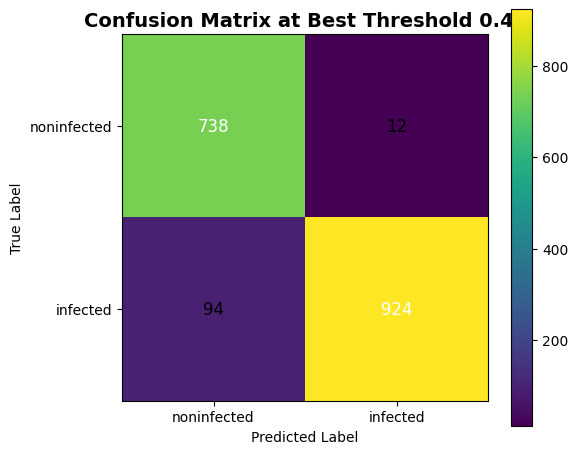

array([[738,  12],
       [ 94, 924]])

In [54]:
# Confusion Matrix at Best Threshold

y_pred_best = (y_prob >= best_threshold).astype(int)

cm_best = confusion_matrix(y_true, y_pred_best)

class_names = ["noninfected", "infected"]

plt.figure(figsize=(6, 5))
plt.imshow(cm_best, cmap="viridis")

plt.title(
    f"Confusion Matrix at Best Threshold {best_threshold:.2f}",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks([0, 1], class_names)
plt.yticks([0, 1], class_names)

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm_best[i, j],
            ha="center",
            va="center",
            fontsize=12,
            color="white" if cm_best[i, j] > cm_best.max() / 2 else "black"
        )

plt.colorbar()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix_best_threshold.png", dpi=300)
plt.show()

cm_best

## Interpretation of the Final Confusion Matrix

The confusion matrix demonstrates strong classification performance on the test dataset.

Most infected and noninfected ultrasound images were classified correctly.

Only a small number of false positive predictions occurred, while false negatives were reduced compared with higher thresholds.

This result indicates that the final CNN model achieved strong generalization performance and reliable medical classification capability.

In [55]:
print(
    classification_report(
        y_true,
        y_pred_best,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

 noninfected     0.8870    0.9840    0.9330       750
    infected     0.9872    0.9077    0.9458      1018

    accuracy                         0.9400      1768
   macro avg     0.9371    0.9458    0.9394      1768
weighted avg     0.9447    0.9400    0.9403      1768



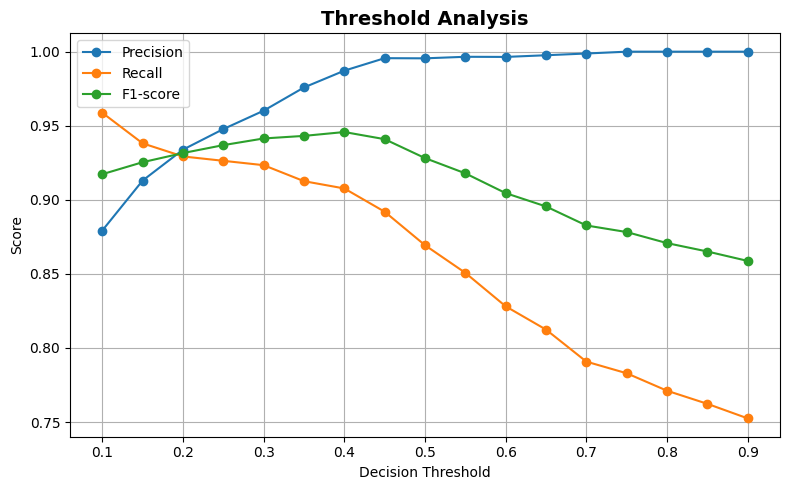

In [51]:
plt.figure(figsize=(8, 5))

plt.plot(threshold_df["threshold"], threshold_df["precision"], marker="o", label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], marker="o", label="Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1_score"], marker="o", label="F1-score")

plt.title("Threshold Analysis", fontsize=14, fontweight="bold")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "threshold_analysis.png", dpi=300)
plt.show()

Evaluation Summary

The final selected CNN model was evaluated on the untouched test dataset to estimate real-world generalization performance.

The evaluation process included:

accuracy
precision
recall
F1-score
AUC (Area Under the ROC Curve)
confusion matrix
ROC curve analysis
decision threshold analysis

Since this is a medical image classification problem for PCOS ultrasound detection, minimizing false negatives is highly important. Therefore, recall was carefully analyzed alongside precision and F1-score.

Threshold analysis was performed to study how different probability thresholds affect the trade-off between sensitivity (recall) and precision. Instead of relying only on the default threshold of 0.50, multiple thresholds were evaluated to identify a more clinically balanced operating point.

Based on the experimental results, a threshold of 0.40 provided the best balance between recall, precision, and overall F1-score performance, making it the final selected threshold for the proposed model.